In [1]:
import numpy as np 
import pandas as pd 
import os
import kagglehub

base = "/kaggle/input"
for ds in os.listdir(base):
    print(f"\n{ds}/")
    for root, dirs, files in os.walk(f"{base}/{ds}"):
        depth = root.replace(f"{base}/{ds}", "").count(os.sep)
        if depth <= 2:
            indent = "  " * (depth + 1)
            print(f"{indent}{os.path.basename(root)}/")
            for f in files[:3]:
                print(f"{indent}  {f}")
            if depth == 2:
                dirs[:] = []


datasets/
  datasets/
    bisusiddharth/
      edda-d1-odir5k-clean/
      edda-d2-mured-clean/
      edda-d3-rfmid-clean/


In [2]:
base = "/kaggle/input/datasets/bisusiddharth"

for ds in os.listdir(base):
    print(f"\n{ds}/")
    for root, dirs, files in os.walk(f"{base}/{ds}"):
        depth = root.replace(f"{base}/{ds}", "").count(os.sep)
        if depth <= 2:
            indent = "  " * (depth + 1)
            print(f"{indent}{os.path.basename(root)}/")
            for f in files[:5]:
                print(f"{indent}  {f}")
            if depth == 2:
                dirs[:] = []


edda-d1-odir5k-clean/
  edda-d1-odir5k-clean/
    D1_clean/
      samples_per_class.png
      blur_distribution.png
      sanity_check_samples.png
      pipeline_funnel.png
      rejected_log.csv
      images/
        d1_normal__image23.jpg
        d1_diabetes__image134.jpg
        d1_diabetes__image1549.jpg
        d1_cataract__image66.jpg
        d1_normal__image905.jpg

edda-d2-mured-clean/
  edda-d2-mured-clean/
    D2_clean/
      samples_per_class.png
      pipeline_funnel.png
      rejected_log.csv
      pipeline_stages_example.png
      qa_verification_report.csv
      images/
        d2_im0057.jpg
        d2_1795.jpg
        d2_aria_d_8_23.jpg
        d2_1030.jpg
        d2_im0001.jpg

edda-d3-rfmid-clean/
  edda-d3-rfmid-clean/
    D3_clean/
      samples_per_class.png
      pipeline_funnel.png
      rejected_log.csv
      disease_risk_split.png
      pipeline_stages_example.png
      images/
        d3_train_85.jpg
        d3_val_333.jpg
        d3_test_138.jpg
        d3_t

In [3]:
D1_ROOT = "/kaggle/input/datasets/bisusiddharth/edda-d1-odir5k-clean/D1_clean"
D2_ROOT = "/kaggle/input/datasets/bisusiddharth/edda-d2-mured-clean/D2_clean"
D3_ROOT = "/kaggle/input/datasets/bisusiddharth/edda-d3-rfmid-clean/D3_clean"

for name, root in [("D1", D1_ROOT), ("D2", D2_ROOT), ("D3", D3_ROOT)]:
    manifest_path = f"{root}/manifest.csv"
    images_path = f"{root}/images"
    print(f"{name}: manifest exists={os.path.exists(manifest_path)}, images dir exists={os.path.exists(images_path)}")

D1: manifest exists=True, images dir exists=True
D2: manifest exists=True, images dir exists=True
D3: manifest exists=True, images dir exists=True


In [4]:
import pandas as pd

d1_manifest = pd.read_csv(f"{D1_ROOT}/manifest.csv")
d2_manifest = pd.read_csv(f"{D2_ROOT}/manifest.csv")
d3_manifest = pd.read_csv(f"{D3_ROOT}/manifest.csv")

print("D1:", d1_manifest.shape, "columns:", d1_manifest.columns.tolist())
print("\nD2:", d2_manifest.shape, "columns:", d2_manifest.columns.tolist())
print("\nD3:", d3_manifest.shape, "columns:", d3_manifest.columns.tolist())

D1: (6388, 10) columns: ['filename', 'source_dataset', 'Normal', 'Diabetes', 'Glaucoma', 'Cataract', 'AMD', 'Myopia', 'Hypertension', 'Others']

D2: (2204, 22) columns: ['filename', 'source_dataset', 'DR', 'NORMAL', 'MH', 'ODC', 'TSLN', 'ARMD', 'DN', 'MYA', 'BRVO', 'ODP', 'CRVO', 'CNV', 'RS', 'ODE', 'LS', 'CSR', 'HTR', 'ASR', 'CRS', 'OTHER']

D3: (3195, 48) columns: ['filename', 'source_dataset', 'disease_risk', 'DR', 'ARMD', 'MH', 'DN', 'MYA', 'BRVO', 'TSLN', 'ERM', 'LS', 'MS', 'CSR', 'ODC', 'CRVO', 'TV', 'AH', 'ODP', 'ODE', 'ST', 'AION', 'PT', 'RT', 'RS', 'CRS', 'EDN', 'RPEC', 'MHL', 'RP', 'CWS', 'CB', 'ODPM', 'PRH', 'MNF', 'HR', 'CRAO', 'TD', 'CME', 'PTCR', 'CF', 'VH', 'MCA', 'VS', 'BRAO', 'PLQ', 'HPED', 'CL']


In [5]:
UNIFIED_LABELS = ["Normal", "DR", "Glaucoma", "AMD", "Myopia"]

def harmonize_d1(df):
    out = pd.DataFrame()
    out["filename"] = df["filename"]
    out["source_dataset"] = "D1"
    out["image_path"] = df["filename"].apply(lambda f: f"{D1_ROOT}/images/{f}")
    out["Normal"] = df["Normal"]
    out["DR"] = df["Diabetes"]
    out["Glaucoma"] = df["Glaucoma"]
    out["AMD"] = df["AMD"]
    out["Myopia"] = df["Myopia"]
    return out

def harmonize_d2(df):
    out = pd.DataFrame()
    out["filename"] = df["filename"]
    out["source_dataset"] = "D2"
    out["image_path"] = df["filename"].apply(lambda f: f"{D2_ROOT}/images/{f}")
    out["Normal"] = df["NORMAL"]
    out["DR"] = df["DR"]
    out["Glaucoma"] = df["ODC"]
    out["AMD"] = df["ARMD"]
    out["Myopia"] = df["MYA"]
    return out

def harmonize_d3(df):
    out = pd.DataFrame()
    out["filename"] = df["filename"]
    out["source_dataset"] = "D3"
    out["image_path"] = df["filename"].apply(lambda f: f"{D3_ROOT}/images/{f}")
    out["Normal"] = (df["disease_risk"] == 0).astype(int)
    out["DR"] = df["DR"]
    out["Glaucoma"] = df["ODC"]
    out["AMD"] = df["ARMD"]
    out["Myopia"] = df["MYA"]
    return out

d1_harm = harmonize_d1(d1_manifest)
d2_harm = harmonize_d2(d2_manifest)
d3_harm = harmonize_d3(d3_manifest)

for name, df in [("D1", d1_harm), ("D2", d2_harm), ("D3", d3_harm)]:
    print(f"\n{name} harmonized shape:", df.shape)
    print(df[UNIFIED_LABELS].sum())


D1 harmonized shape: (6388, 8)
Normal      2871
DR          1608
Glaucoma     284
AMD          266
Myopia       232
dtype: int64

D2 harmonized shape: (2204, 8)
Normal      492
DR          495
Glaucoma    263
AMD         158
Myopia       89
dtype: int64

D3 harmonized shape: (3195, 8)
Normal      667
DR          632
Glaucoma    445
AMD         169
Myopia      167
dtype: int64


In [6]:
for name, df in [("D1", d1_harm), ("D2", d2_harm), ("D3", d3_harm)]:
    label_sums = df[UNIFIED_LABELS].sum(axis=1)
    print(f"\n{name}:")
    print(f"  Images with 0 active unified labels: {(label_sums == 0).sum()}")
    print(f"  Images with exactly 1 active label: {(label_sums == 1).sum()}")
    print(f"  Images with 2+ active labels: {(label_sums >= 2).sum()}")


D1:
  Images with 0 active unified labels: 1127
  Images with exactly 1 active label: 5261
  Images with 2+ active labels: 0

D2:
  Images with 0 active unified labels: 787
  Images with exactly 1 active label: 1342
  Images with 2+ active labels: 75

D3:
  Images with 0 active unified labels: 1272
  Images with exactly 1 active label: 1776
  Images with 2+ active labels: 147


In [7]:
def filter_in_scope(df, name):
    label_sums = df[UNIFIED_LABELS].sum(axis=1)
    in_scope = df[label_sums > 0].reset_index(drop=True)
    dropped = len(df) - len(in_scope)
    print(f"{name}: {len(df)} -> {len(in_scope)} (dropped {dropped} out-of-scope images)")
    return in_scope

d1_final = filter_in_scope(d1_harm, "D1")
d2_final = filter_in_scope(d2_harm, "D2")
d3_final = filter_in_scope(d3_harm, "D3")

print("\nFinal per-class counts:")
for name, df in [("D1", d1_final), ("D2", d2_final), ("D3", d3_final)]:
    print(f"\n{name}:")
    print(df[UNIFIED_LABELS].sum())

D1: 6388 -> 5261 (dropped 1127 out-of-scope images)
D2: 2204 -> 1417 (dropped 787 out-of-scope images)
D3: 3195 -> 1923 (dropped 1272 out-of-scope images)

Final per-class counts:

D1:
Normal      2871
DR          1608
Glaucoma     284
AMD          266
Myopia       232
dtype: int64

D2:
Normal      492
DR          495
Glaucoma    263
AMD         158
Myopia       89
dtype: int64

D3:
Normal      667
DR          632
Glaucoma    445
AMD         169
Myopia      167
dtype: int64


In [8]:
import hashlib
from PIL import Image
import imagehash
from tqdm import tqdm

def file_hash(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

def compute_hashes(df, name):
    exact_hashes = {}
    phashes = {}
    for _, row in tqdm(df.iterrows(), total=len(df), desc=f"Hashing {name}"):
        path = row["image_path"]
        exact_hashes[row["filename"]] = file_hash(path)
        phashes[row["filename"]] = imagehash.phash(Image.open(path))
    return exact_hashes, phashes

d1_exact, d1_phash = compute_hashes(d1_final, "D1")
d2_exact, d2_phash = compute_hashes(d2_final, "D2")
d3_exact, d3_phash = compute_hashes(d3_final, "D3")

print("Hashing complete:", len(d1_exact), len(d2_exact), len(d3_exact))

Hashing D3: 100%|██████████| 1923/1923 [00:17<00:00, 107.96it/s]

Hashing complete: 5261 1417 1923


In [9]:
def find_cross_duplicates(hashesA, hashesB, nameA, nameB):
    # invert B's hash dict for fast lookup: hash -> filename
    reverse_B = {}
    for fname, h in hashesB.items():
        reverse_B.setdefault(h, []).append(fname)

    matches = []
    for fnameA, hA in hashesA.items():
        if hA in reverse_B:
            for fnameB in reverse_B[hA]:
                matches.append((fnameA, fnameB))
    print(f"{nameA} <-> {nameB}: {len(matches)} matching pairs")
    return matches

print("="*60)
print("EXACT HASH (byte-identical) cross-dataset matches")
print("="*60)
exact_d1_d2 = find_cross_duplicates(d1_exact, d2_exact, "D1", "D2")
exact_d1_d3 = find_cross_duplicates(d1_exact, d3_exact, "D1", "D3")
exact_d2_d3 = find_cross_duplicates(d2_exact, d3_exact, "D2", "D3")

print("\n" + "="*60)
print("PERCEPTUAL HASH (visually-identical) cross-dataset matches")
print("="*60)
phash_d1_d2 = find_cross_duplicates(d1_phash, d2_phash, "D1", "D2")
phash_d1_d3 = find_cross_duplicates(d1_phash, d3_phash, "D1", "D3")
phash_d2_d3 = find_cross_duplicates(d2_phash, d3_phash, "D2", "D3")

EXACT HASH (byte-identical) cross-dataset matches
D1 <-> D2: 0 matching pairs
D1 <-> D3: 0 matching pairs
D2 <-> D3: 0 matching pairs

PERCEPTUAL HASH (visually-identical) cross-dataset matches
D1 <-> D2: 0 matching pairs
D1 <-> D3: 0 matching pairs
D2 <-> D3: 200 matching pairs


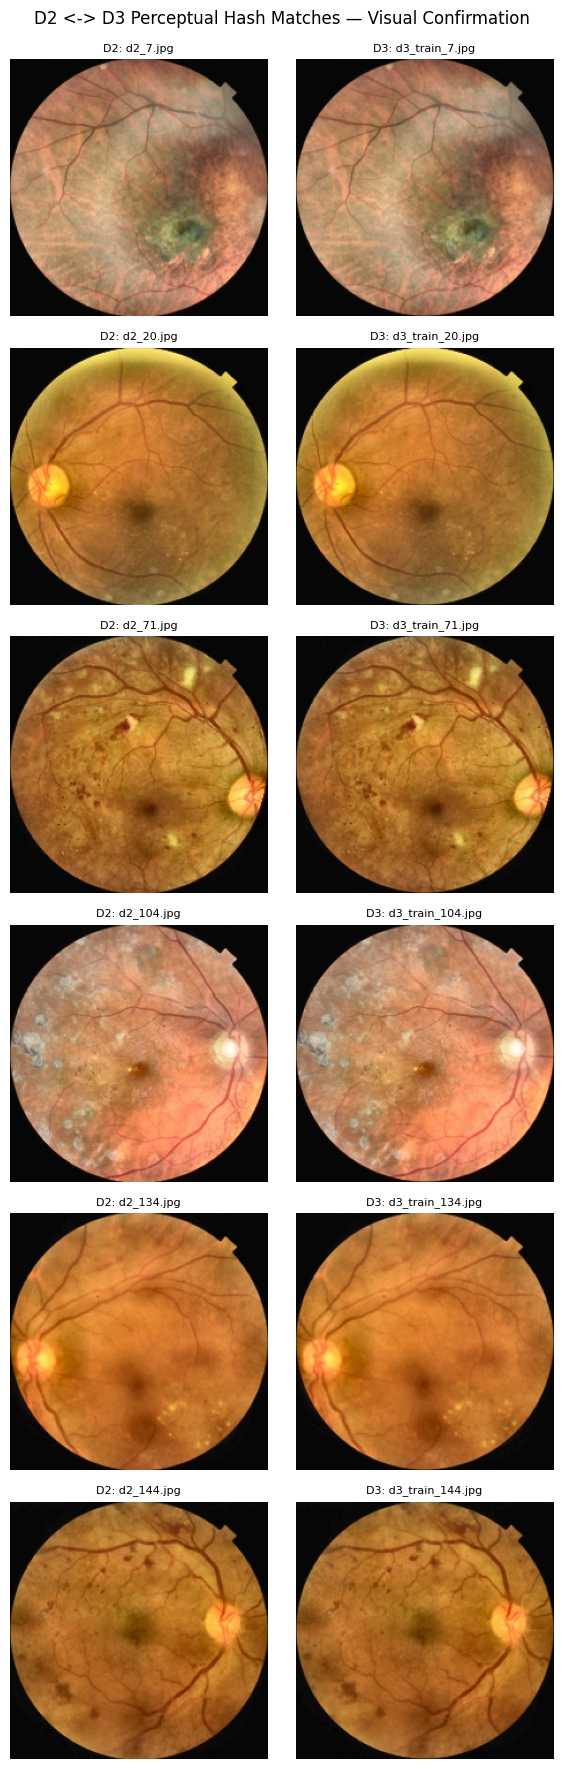

In [10]:
import matplotlib.pyplot as plt

sample_pairs = phash_d2_d3[:6]  # first 6 for inspection

fig, axes = plt.subplots(len(sample_pairs), 2, figsize=(6, 3*len(sample_pairs)))
for i, (d2_fname, d3_fname) in enumerate(sample_pairs):
    d2_path = d2_final[d2_final["filename"] == d2_fname]["image_path"].iloc[0]
    d3_path = d3_final[d3_final["filename"] == d3_fname]["image_path"].iloc[0]

    img_d2 = Image.open(d2_path)
    img_d3 = Image.open(d3_path)

    axes[i, 0].imshow(img_d2); axes[i, 0].set_title(f"D2: {d2_fname}", fontsize=8); axes[i, 0].axis("off")
    axes[i, 1].imshow(img_d3); axes[i, 1].set_title(f"D3: {d3_fname}", fontsize=8); axes[i, 1].axis("off")

plt.suptitle("D2 <-> D3 Perceptual Hash Matches — Visual Confirmation\n")
plt.tight_layout()
plt.show()

In [11]:
d2_duplicate_filenames = set(d2_fname for d2_fname, d3_fname in phash_d2_d3)
print("D2 images to drop (duplicated in D3):", len(d2_duplicate_filenames))

d2_deduped = d2_final[~d2_final["filename"].isin(d2_duplicate_filenames)].reset_index(drop=True)
print(f"D2: {len(d2_final)} -> {len(d2_deduped)} (dropped {len(d2_final) - len(d2_deduped)} cross-dataset duplicates)")

D2 images to drop (duplicated in D3): 200
D2: 1417 -> 1217 (dropped 200 cross-dataset duplicates)


In [12]:
print("D2 final shape:", d2_deduped.shape)
print(d2_deduped[UNIFIED_LABELS].sum())

# sanity check: confirm none of the dropped filenames remain
remaining_overlap = set(d2_deduped["filename"]) & d2_duplicate_filenames
print("\nRemaining overlap (should be 0):", len(remaining_overlap))

D2 final shape: (1217, 8)
Normal      425
DR          421
Glaucoma    228
AMD         137
Myopia       78
dtype: int64

Remaining overlap (should be 0): 0


In [13]:
# rename for clarity going forward
d1 = d1_final.copy()
d2 = d2_deduped.copy()
d3 = d3_final.copy()

variants = {
    "D1": d1,
    "D2": d2,
    "D3": d3,
    "D12": pd.concat([d1, d2], ignore_index=True),
    "D13": pd.concat([d1, d3], ignore_index=True),
    "D23": pd.concat([d2, d3], ignore_index=True),
    "D123": pd.concat([d1, d2, d3], ignore_index=True),
}

OUTPUT_DIR = "/kaggle/working/harmonized"
os.makedirs(OUTPUT_DIR, exist_ok=True)

for name, df in variants.items():
    out_path = f"{OUTPUT_DIR}/manifest_{name}.csv"
    df.to_csv(out_path, index=False)
    print(f"{name}: {df.shape[0]} images -> saved to {out_path}")
    print(df[UNIFIED_LABELS].sum().to_dict())
    print()

D1: 5261 images -> saved to /kaggle/working/harmonized/manifest_D1.csv
{'Normal': 2871, 'DR': 1608, 'Glaucoma': 284, 'AMD': 266, 'Myopia': 232}

D2: 1217 images -> saved to /kaggle/working/harmonized/manifest_D2.csv
{'Normal': 425, 'DR': 421, 'Glaucoma': 228, 'AMD': 137, 'Myopia': 78}

D3: 1923 images -> saved to /kaggle/working/harmonized/manifest_D3.csv
{'Normal': 667, 'DR': 632, 'Glaucoma': 445, 'AMD': 169, 'Myopia': 167}

D12: 6478 images -> saved to /kaggle/working/harmonized/manifest_D12.csv
{'Normal': 3296, 'DR': 2029, 'Glaucoma': 512, 'AMD': 403, 'Myopia': 310}

D13: 7184 images -> saved to /kaggle/working/harmonized/manifest_D13.csv
{'Normal': 3538, 'DR': 2240, 'Glaucoma': 729, 'AMD': 435, 'Myopia': 399}

D23: 3140 images -> saved to /kaggle/working/harmonized/manifest_D23.csv
{'Normal': 1092, 'DR': 1053, 'Glaucoma': 673, 'AMD': 306, 'Myopia': 245}

D123: 8401 images -> saved to /kaggle/working/harmonized/manifest_D123.csv
{'Normal': 3963, 'DR': 2661, 'Glaucoma': 957, 'AMD': 5

In [14]:
print("="*60)
print("FINAL VERIFICATION: image path resolution across all 7 variants")
print("="*60)

for name, df in variants.items():
    missing = [p for p in df["image_path"] if not os.path.exists(p)]
    print(f"{name}: {len(df)} total, {len(missing)} missing files", 
          "PASS" if len(missing) == 0 else f"FAIL - examples: {missing[:3]}")

FINAL VERIFICATION: image path resolution across all 7 variants
D1: 5261 total, 0 missing files PASS
D2: 1217 total, 0 missing files PASS
D3: 1923 total, 0 missing files PASS
D12: 6478 total, 0 missing files PASS
D13: 7184 total, 0 missing files PASS
D23: 3140 total, 0 missing files PASS
D123: 8401 total, 0 missing files PASS


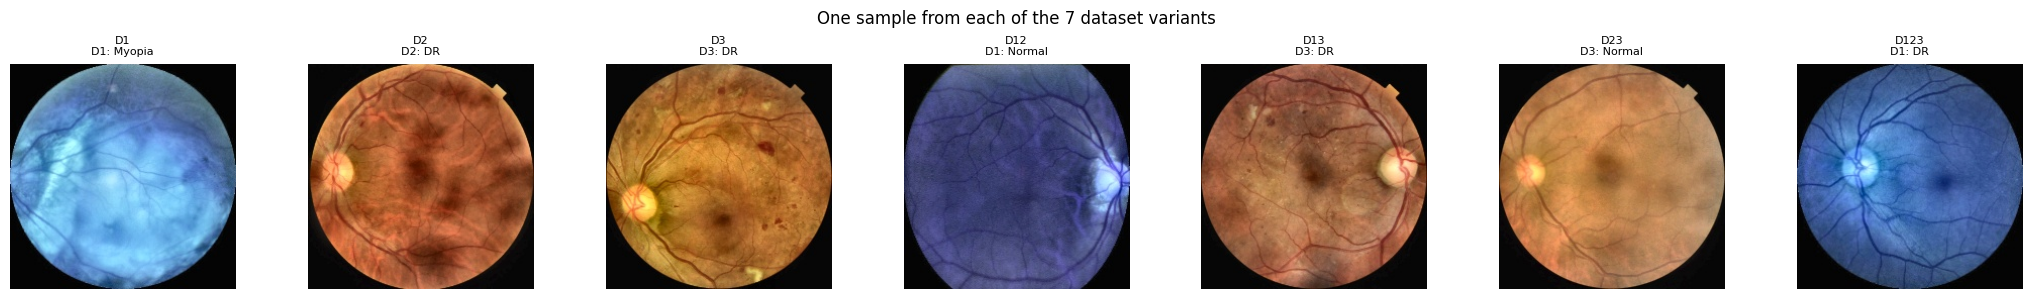

In [15]:
fig, axes = plt.subplots(1, 7, figsize=(21, 3))
for ax, (name, df) in zip(axes, variants.items()):
    row = df.sample(1, random_state=1).iloc[0]
    img = Image.open(row["image_path"])
    active = [c for c in UNIFIED_LABELS if row[c] == 1]
    ax.imshow(img)
    ax.set_title(f"{name}\n{row['source_dataset']}: {', '.join(active)}", fontsize=8)
    ax.axis("off")
plt.suptitle("One sample from each of the 7 dataset variants")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/variant_samples_check.png", dpi=150, bbox_inches="tight")
plt.show()